Subsidy removal (May 2023)
       commodity  before  after  n_before  n_after  change  pct_change
0  Beans (white)   432.8  542.5         3        3   109.7        25.3
1    Maize flour   275.3  373.1         3        3    97.8        35.5
2         Millet   251.3  323.4         3        3    72.1        28.7
3   Rice (local)   630.3  685.8         3        3    55.5         8.8
4        Sorghum   235.7  314.5         3        3    78.8        33.4
5            Yam   270.0  366.1         3        3    96.2        35.6
   state  before  after  n_before  n_after  change  pct_change
0  Borno   385.3  454.1         3        3    68.8        17.9
1   Yobe   313.2  414.4         3        3   101.2        32.3
Naira float (June 2023)
       commodity  before  after  n_before  n_after  change  pct_change
0  Beans (white)   458.6  575.6         3        3   117.0        25.5
1    Maize flour   285.0  451.5         3        3   166.5        58.4
2         Millet   267.4  372.5         3        3

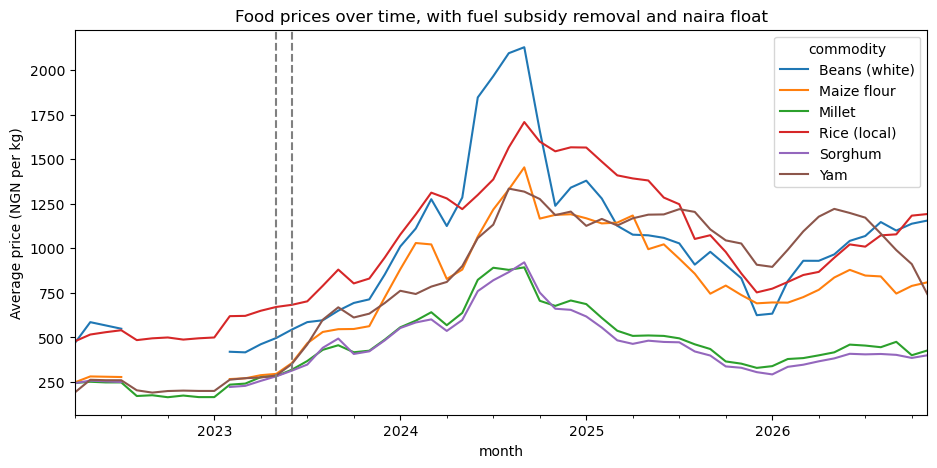

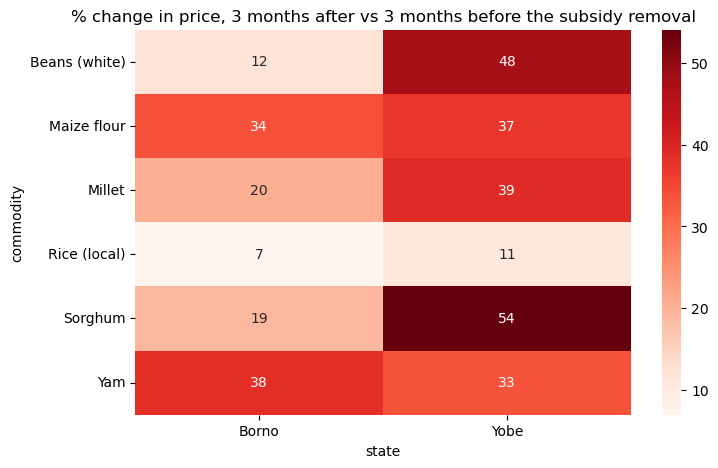

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


food = pd.read_csv('../data/processed/food_clean.csv', parse_dates=['month'])


EVENTS = {
    'Subsidy removal (May 2023)': pd.Timestamp('2023-05-01'),
    'Naira float (June 2023)': pd.Timestamp('2023-06-01'),
}


def before_after(df, event, n, by):
    before = df[(df['month'] >= event - pd.DateOffset(months=n)) & (df['month'] < event)]
    after = df[(df['month'] >= event) & (df['month'] < event + pd.DateOffset(months=n))]
    b = before.groupby(by)['price_ngn'].mean().rename('before')
    a = after.groupby(by)['price_ngn'].mean().rename('after')
    nb = before.groupby(by)['month'].nunique().rename('n_before')   # months actually used
    na = after.groupby(by)['month'].nunique().rename('n_after')
    out = pd.concat([b, a, nb, na], axis=1)
    out['change'] = out['after'] - out['before']
    out['pct_change'] = 100 * out['change'] / out['before']
    return out.reset_index()


# Full results: every event, window and state-commodity pair
rows = []
for ev_name, ev_date in EVENTS.items():
    for n in [3, 6, 12]:
        t = before_after(food, ev_date, n, ['state', 'commodity'])
        t['event'] = ev_name
        t['window_months'] = n
        rows.append(t)
results = pd.concat(rows, ignore_index=True)
results.to_csv('../reports/descriptive_results.csv', index=False)


# Tables for the report: by commodity, and by state (3-month window)
for ev_name, ev_date in EVENTS.items():
    print(ev_name)
    print(before_after(food, ev_date, 3, ['commodity']).round(1))
    print(before_after(food, ev_date, 3, ['state']).round(1))


# Chart 1: price trends with event lines
avg = food.groupby(['month', 'commodity'])['price_ngn'].mean().unstack()
ax = avg.plot(figsize=(11, 5))
for ev_name, ev_date in EVENTS.items():
    ax.axvline(ev_date, linestyle='--', color='grey')
ax.set_ylabel('Average price (NGN per kg)')
ax.set_title('Food prices over time, with fuel subsidy removal and naira float')
plt.savefig('../reports/figures/price_trends.png', dpi=200, bbox_inches='tight')
plt.show()


# Chart 2: heatmap of % change, 3 months before vs 3 months after the subsidy removal
first_event = list(EVENTS)[0]
heat = results[(results['event'] == first_event) & (results['window_months'] == 3)]
heat = heat.pivot(index='commodity', columns='state', values='pct_change')
plt.figure(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='Reds')
plt.title('% change in price, 3 months after vs 3 months before the subsidy removal')
plt.savefig('../reports/figures/pct_change_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()